# Step 1: Importing Libraries

In this step we import all the libraries we need for this project.
Librosa is used to read and process audio files. Sklearn is used 
to build and evaluate the machine learning model.

In [30]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import soundfile as sf
import os
import glob
import warnings
warnings.filterwarnings('ignore')

print("All imports done")

All imports done


# Step 2: Loading the Dataset Paths and Extracting Labels

RAVDESS audio files have the emotion label hidden inside the file name.
For example in the file 03-01-05-01-02-01-12.wav the third segment (05)
represents the emotion. We loop through all audio files and extract 
that emotion code from each file name to build our labels list.

Emotion codes:
01 = neutral, 02 = calm, 03 = happy, 04 = sad
05 = angry, 06 = fearful, 07 = disgust, 08 = surprised

In [31]:
emotion_map = {
    '01': 'neutral',
    '02': 'calm',
    '03': 'happy',
    '04': 'sad',
    '05': 'angry',
    '06': 'fearful',
    '07': 'disgust',
    '08': 'surprised'
}

file_paths = []
labels = []

audio_files = glob.glob("Actor_*/*.wav")

for filepath in audio_files:
    filename = os.path.basename(filepath)
    parts = filename.split('-')
    emotion_code = parts[2]
    emotion = emotion_map[emotion_code]
    file_paths.append(filepath)
    labels.append(emotion)

print("Total files loaded:", len(file_paths))
print("Total labels loaded:", len(labels))

Total files loaded: 1440
Total labels loaded: 1440


# Step 3: Checking Emotion Distribution

Before building the model we want to see how many audio files 
exist for each emotion. This tells us if the dataset is balanced 
meaning each emotion has a similar number of samples or not.

Emotion distribution:
calm         192
happy        192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
neutral       96
Name: count, dtype: int64


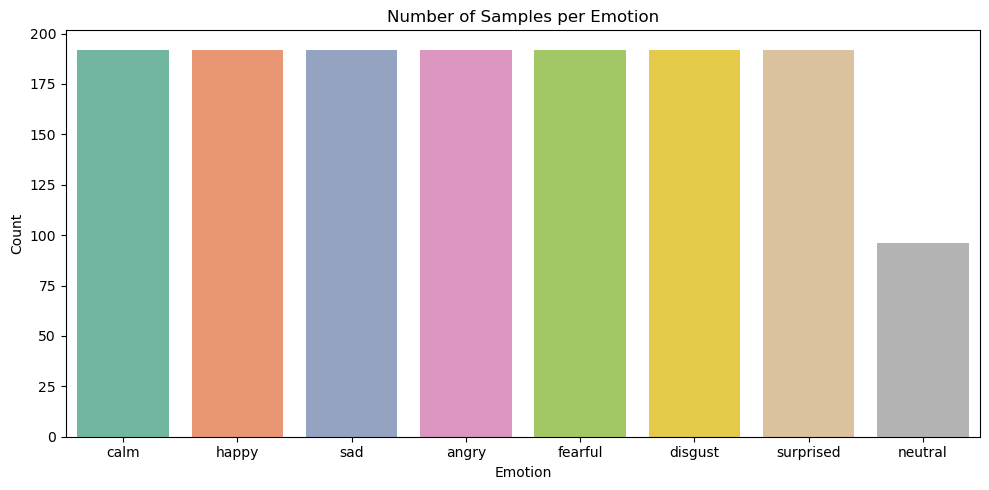

In [32]:
emotion_counts = pd.Series(labels).value_counts()
print("Emotion distribution:")
print(emotion_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=emotion_counts.index, y=emotion_counts.values, palette='Set2')
plt.title('Number of Samples per Emotion')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Step 4: Listening and Visualizing One Audio File

Here we load one audio file and visualize it in two ways.
The waveform shows how the sound volume changes over time.
The spectrogram shows the frequencies present in the audio over time.
This helps us understand what the raw audio looks like before 
we convert it into numbers for the model.

File: Actor_01\03-01-01-01-01-01-01.wav
Emotion: neutral
Sample rate: 22050
Audio length: 66150


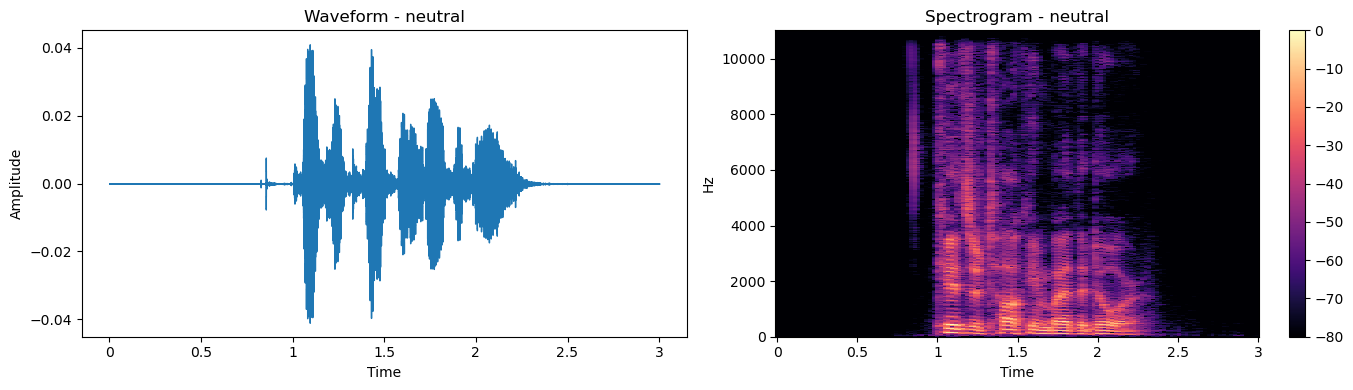

In [33]:
sample_file = file_paths[0]
sample_label = labels[0]

audio, sample_rate = librosa.load(sample_file, duration=3)

print("File:", sample_file)
print("Emotion:", sample_label)
print("Sample rate:", sample_rate)
print("Audio length:", len(audio))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].set_title('Waveform - ' + sample_label)
librosa.display.waveshow(audio, sr=sample_rate, ax=axes[0])
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Amplitude')

spectrogram = librosa.amplitude_to_db(
    np.abs(librosa.stft(audio)), ref=np.max
)
img = librosa.display.specshow(
    spectrogram, sr=sample_rate,
    x_axis='time', y_axis='hz', ax=axes[1]
)
axes[1].set_title('Spectrogram - ' + sample_label)
fig.colorbar(img, ax=axes[1])

plt.tight_layout()
plt.show()

# Step 5: Understanding MFCCs

MFCCs convert an audio file into a fixed set of numbers that 
represent the key characteristics of the sound. We visualize 
the MFCCs of one audio file here to understand what they 
look like before extracting them from all 1440 files.

MFCC shape for one file: (40, 130)
This means 40 coefficients across 130 time frames


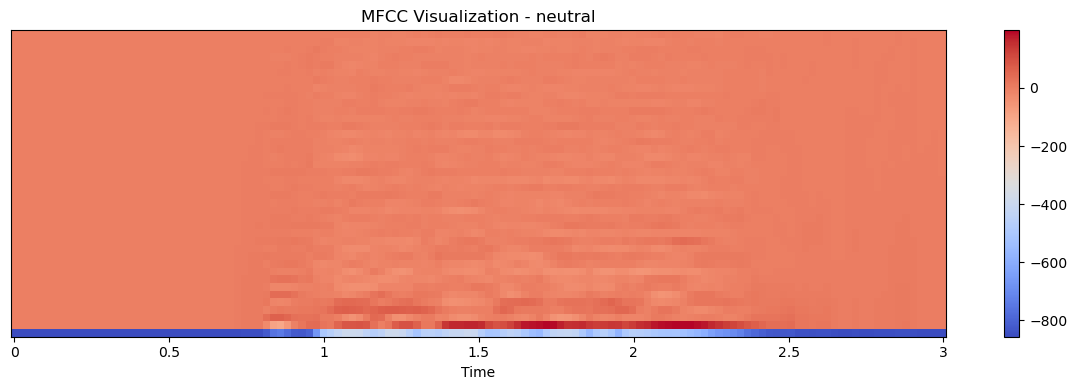

In [34]:
sample_audio, sample_rate = librosa.load(file_paths[0], duration=3)

mfcc = librosa.feature.mfcc(y=sample_audio, sr=sample_rate, n_mfcc=40)

print("MFCC shape for one file:", mfcc.shape)
print("This means 40 coefficients across", mfcc.shape[1], "time frames")

plt.figure(figsize=(12, 4))
librosa.display.specshow(mfcc, sr=sample_rate, x_axis='time')
plt.colorbar()
plt.title('MFCC Visualization - ' + labels[0])
plt.tight_layout()
plt.show()

# Step 6: Extracting MFCC Features from All Audio Files

Here we loop through all 1440 audio files and extract MFCC features 
from each one. For every file we take the mean of the 40 MFCC 
coefficients across time. This gives us one row of 40 numbers 
per audio file. At the end we have a table of 1440 rows and 
40 columns which we will use to train our model.

This cell will take 2 to 5 minutes to run. Please wait.

In [35]:
def extract_mfcc(filepath):
    audio, sample_rate = librosa.load(filepath, duration=3, offset=0.5)
    mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
    mfcc_mean = np.mean(mfcc.T, axis=0)
    return mfcc_mean

features = []
failed = 0

for i, filepath in enumerate(file_paths):
    try:
        mfcc_features = extract_mfcc(filepath)
        features.append(mfcc_features)
    except Exception as e:
        failed += 1

    if (i+1) % 100 == 0:
        print(f"Processed {i+1} / {len(file_paths)} files")

print("Feature extraction complete")
print("Total files processed:", len(features))
print("Failed files:", failed)

Processed 100 / 1440 files
Processed 200 / 1440 files
Processed 300 / 1440 files
Processed 400 / 1440 files
Processed 500 / 1440 files
Processed 600 / 1440 files
Processed 700 / 1440 files
Processed 800 / 1440 files
Processed 900 / 1440 files
Processed 1000 / 1440 files
Processed 1100 / 1440 files
Processed 1200 / 1440 files
Processed 1300 / 1440 files
Processed 1400 / 1440 files
Feature extraction complete
Total files processed: 1440
Failed files: 0


# Step 7: Converting Features into a DataFrame

Now we convert the extracted features into a proper table format 
using pandas DataFrame. Each row is one audio file and each column 
is one MFCC value. We also attach the emotion labels to this table 
so we can use it for training.

In [36]:
X = np.array(features)
y = np.array(labels)

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Sample feature row:", X[0])
print("Sample label:", y[0])

feature_df = pd.DataFrame(X)
feature_df['emotion'] = y

print("\nDataset preview:")
feature_df.head()

Features shape: (1440, 40)
Labels shape: (1440,)
Sample feature row: [-6.7019543e+02  6.5063850e+01  8.8895434e-01  1.4715979e+01
  9.1821651e+00  6.6057467e-01 -3.8468361e+00 -3.5839462e+00
 -1.2959006e+01 -3.3001330e+00  9.1077948e-01 -3.5970356e+00
  2.3762746e+00 -4.3889413e+00  5.4508036e-01  8.9185190e-01
 -4.8025908e+00 -2.1054137e+00 -1.6059692e+00 -1.0523903e+00
 -7.0672808e+00 -6.2306100e-01 -2.7280297e+00 -5.3073611e+00
 -1.9691167e+00 -9.4615275e-01 -5.7211108e+00  3.3299112e-01
 -2.5438452e+00  1.8220831e-01 -2.3510973e+00 -2.5047269e+00
 -3.1515074e+00 -2.1908989e+00 -3.8017602e+00 -1.8130876e+00
 -1.2612224e+00 -2.1449544e+00 -4.1521730e+00 -1.7796154e+00]
Sample label: neutral

Dataset preview:


,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,emotion
0,-670.195435,65.063850,0.888954,14.715979,9.182165,0.660575,-3.846836,-3.583946,-12.959006,-3.300133,...,-2.504727,-3.151507,-2.190899,-3.801760,-1.813088,-1.261222,-2.144954,-4.152173,-1.779615,neutral
1,-660.230347,63.325817,-2.630457,17.983355,9.407704,-0.981498,-2.324697,-6.848032,-14.133670,-2.200332,...,-3.113372,-2.556751,-2.935113,-3.654963,-0.988048,-1.499825,-3.617125,-3.751694,-2.730914,neutral
2,-661.964478,66.655869,-0.932158,14.899042,5.324703,0.474343,-3.346651,-7.102525,-12.873403,-5.088379,...,-2.643650,-2.937167,-2.361648,-3.345104,-2.426059,-1.460013,-3.281310,-4.208613,-2.726205,neutral
3,-657.722351,65.035187,3.148672,15.666511,7.582657,2.628088,-1.850069,-7.477578,-11.976265,-4.458463,...,-2.849612,-3.591487,-3.104016,-3.495707,-1.628411,-1.304878,-3.032794,-3.973964,-3.861779,neutral
4,-694.579590,72.531715,3.104562,17.112118,9.077339,1.836257,-4.146086,-4.797151,-11.764124,-5.925480,...,-1.405873,-2.290345,-2.879143,-2.069092,-0.544464,-2.073817,-2.080611,-4.573941,-3.246941,calm


# Step 8: Encoding Labels and Splitting the Data

Before training, we need to convert emotion names into numbers 
because machine learning models only understand numbers. 
We also split the data into training and testing sets.
80% of data will be used for training and 20% for testing.

In [37]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Emotion classes:", le.classes_)
print("Encoded values:", np.unique(y_encoded))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Emotion classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']
Encoded values: [0 1 2 3 4 5 6 7]

Training set size: (1152, 40)
Testing set size: (288, 40)


# Step 9: Scaling the Features

Just like in Task 1 we scale the features so that all MFCC values 
are in the same range. This helps the model learn better and faster.
Without scaling some large MFCC values would dominate the smaller ones.

In [38]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling done")
print("Mean of training data after scaling:", X_train.mean().round(4))
print("Std of training data after scaling:", X_train.std().round(4))

Scaling done
Mean of training data after scaling: 0.0
Std of training data after scaling: 1.0


# Step 10: Training Model 1 - Random Forest

Random Forest builds multiple decision trees and combines their 
results. We already used this in Task 1. Here we apply the same 
idea but on audio features instead of financial data.
n_estimators=200 means we are building 200 decision trees.

In [39]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_accuracy = rf_model.score(X_test, y_test) * 100

print("Random Forest Training done")
print(f"Accuracy: {rf_accuracy:.2f}%")

Random Forest Training done
Accuracy: 60.42%


# Step 11: Training Model 2 - MLP Neural Network

MLP stands for Multi Layer Perceptron. It is a simple neural network 
that works well for this kind of task. It has hidden layers that learn 
patterns from the MFCC features. We use two hidden layers with 
256 and 128 neurons. This will take 1 to 2 minutes to train.

In [40]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation='relu',
    max_iter=300,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

mlp_model.fit(X_train, y_train)

mlp_pred = mlp_model.predict(X_test)
mlp_accuracy = mlp_model.score(X_test, y_test) * 100

print("MLP Neural Network Training done")
print(f"Accuracy: {mlp_accuracy:.2f}%")

MLP Neural Network Training done
Accuracy: 60.42%


# Step 12: Comparing Both Models

Here we compare the accuracy of both models side by side 
to see which one performed better on the emotion recognition task.

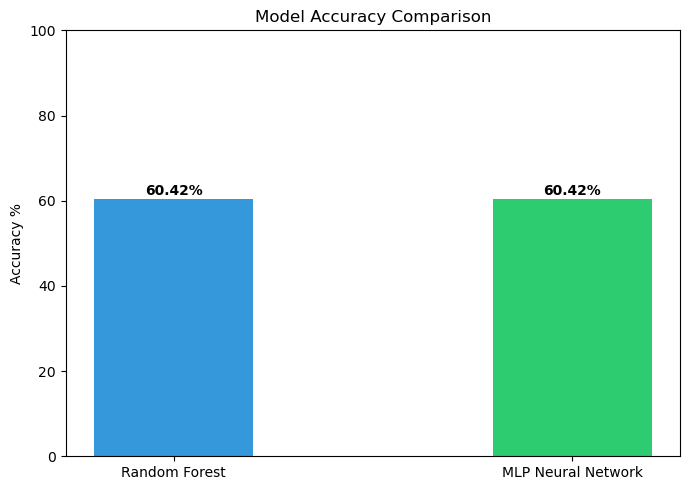

Best model: Random Forest
Best accuracy: 60.42%


In [41]:
model_names = ['Random Forest', 'MLP Neural Network']
accuracies = [rf_accuracy, mlp_accuracy]

plt.figure(figsize=(7, 5))
bars = plt.bar(model_names, accuracies, color=['#3498db', '#2ecc71'], width=0.4)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy %')
plt.ylim(0, 100)

for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{acc:.2f}%',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

best_model = model_names[np.argmax(accuracies)]
print("Best model:", best_model)
print(f"Best accuracy: {max(accuracies):.2f}%")

# Step 13: Detailed Evaluation - Classification Report

Accuracy alone does not tell the full story. Here we look at 
precision, recall and f1-score for each emotion separately.
This tells us which emotions the model is good at recognizing 
and which ones it struggles with.

In [42]:
print("Classification Report - MLP Neural Network")
print("=" * 55)
print(classification_report(
    y_test,
    mlp_pred,
    target_names=le.classes_
))

Classification Report - MLP Neural Network
              precision    recall  f1-score   support

       angry       0.79      0.82      0.81        38
        calm       0.65      0.63      0.64        38
     disgust       0.55      0.61      0.57        38
     fearful       0.65      0.67      0.66        39
       happy       0.57      0.44      0.49        39
     neutral       0.39      0.47      0.43        19
         sad       0.57      0.63      0.60        38
   surprised       0.57      0.51      0.54        39

    accuracy                           0.60       288
   macro avg       0.59      0.60      0.59       288
weighted avg       0.61      0.60      0.60       288



# Step 14: Confusion Matrix

A confusion matrix shows us exactly where the model is making 
mistakes. Each row represents the actual emotion and each column 
represents what the model predicted. The diagonal cells show 
correct predictions. Off diagonal cells show where the model 
confused one emotion for another.

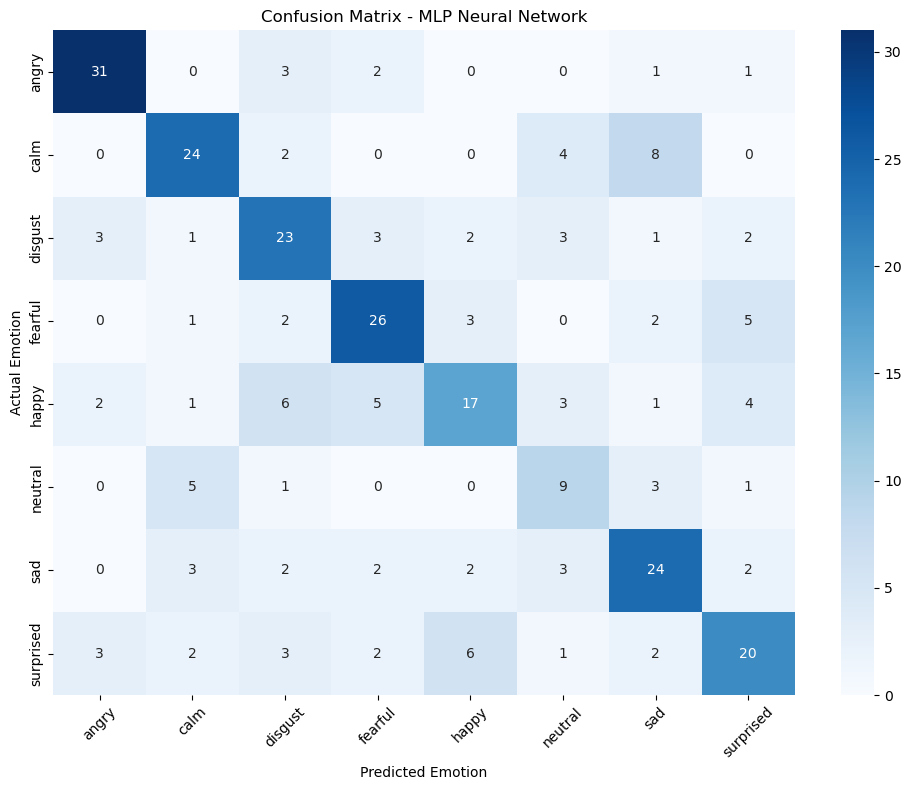

In [43]:
cm = confusion_matrix(y_test, mlp_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Confusion Matrix - MLP Neural Network')
plt.ylabel('Actual Emotion')
plt.xlabel('Predicted Emotion')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 15: Saving the Model

We save the trained MLP model and the scaler to disk so we can 
load them later without retraining. We also save the label encoder 
so we can convert predicted numbers back to emotion names.

In [44]:
import joblib

joblib.dump(mlp_model, 'emotion_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Model saved as emotion_model.pkl")
print("Scaler saved as scaler.pkl")
print("Label encoder saved as label_encoder.pkl")

Model saved as emotion_model.pkl
Scaler saved as scaler.pkl
Label encoder saved as label_encoder.pkl


# Step 16: Interactive Emotion Recognition App

Here we build an app where the user can provide any .wav audio 
file path and the model will predict the emotion in that audio.
The app extracts MFCC features from the given file, scales them,
and passes them through our trained MLP model to get the prediction.

In [45]:
import ipywidgets as widgets
from IPython.display import display, clear_output, Audio

title = widgets.HTML("<h3 style='color:#2c3e50'>Emotion Recognition from Speech</h3>")

file_input = widgets.Text(
    value='',
    placeholder='Enter path to your .wav file e.g. Actor_01/03-01-05-01-01-01-01.wav',
    description='Audio File:',
    style={'description_width': '100px'},
    layout=widgets.Layout(width='600px')
)

button = widgets.Button(
    description='Predict Emotion',
    button_style='primary',
    layout=widgets.Layout(width='200px')
)

output = widgets.Output()

def predict_emotion(b):
    with output:
        clear_output()

        filepath = file_input.value.strip()

        if not os.path.exists(filepath):
            print("File not found. Please check the path and try again.")
            return

        try:
            audio, sample_rate = librosa.load(filepath, duration=3, offset=0.5)
            mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
            mfcc_mean = np.mean(mfcc.T, axis=0).reshape(1, -1)
            mfcc_scaled = scaler.transform(mfcc_mean)

            prediction = mlp_model.predict(mfcc_scaled)[0]
            probabilities = mlp_model.predict_proba(mfcc_scaled)[0]
            emotion_label = le.inverse_transform([prediction])[0]
            confidence = probabilities[prediction] * 100

            print("=" * 40)
            print("       EMOTION RECOGNITION RESULT")
            print("=" * 40)
            print(f"  File      : {os.path.basename(filepath)}")
            print(f"  Predicted : {emotion_label.upper()}")
            print(f"  Confidence: {confidence:.1f}%")
            print("=" * 40)

            print("\nAll emotion probabilities:")
            prob_df = pd.DataFrame({
                'Emotion': le.classes_,
                'Probability': probabilities * 100
            }).sort_values('Probability', ascending=False)

            for _, row in prob_df.iterrows():
                bar = '#' * int(row['Probability'] / 5)
                print(f"  {row['Emotion']:12} {row['Probability']:5.1f}%  {bar}")

            print("\nAudio preview:")
            display(Audio(filepath))

        except Exception as e:
            print("Something went wrong:", str(e))

button.on_click(predict_emotion)

display(title, file_input, button, output)

HTML(value="<h3 style='color:#2c3e50'>Emotion Recognition from Speech</h3>")

Text(value='', description='Audio File:', layout=Layout(width='600px'), placeholder='Enter path to your .wav f…

Button(button_style='primary', description='Predict Emotion', layout=Layout(width='200px'), style=ButtonStyle(…

Output()